# Patient-Grouped Baseline CNN

This notebook rebuilds the baseline convolutional neural network using the cleaned, patient-grouped CBIS-DDSM training and validation split. The patient-level partition prevents overlap between training and validation cases and provides the corrected baseline used for subsequent model comparison and threshold analysis.

In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

# Dataset location
# Set the CBIS_DDSM_DIR environment variable to override the default path
DATASET_DIR = os.environ.get(
    "CBIS_DDSM_DIR",
    os.path.join("..", "data", "CBIS-DDSM")
)

CSV_DIR = os.path.join(DATASET_DIR, "csv")
JPEG_DIR = os.path.join(DATASET_DIR, "jpeg")

print("CSV folder exists:", os.path.exists(CSV_DIR))
print("JPEG folder exists:", os.path.exists(JPEG_DIR))
print("CSV files:", os.listdir(CSV_DIR))

CSV folder exists: True
JPEG folder exists: True
CSV files: ['calc_case_description_test_set.csv', 'calc_case_description_train_set.csv', 'dicom_info.csv', 'mass_case_description_test_set.csv', 'mass_case_description_train_set.csv', 'meta.csv']


In [3]:
train_mass = pd.read_csv(
    os.path.join(CSV_DIR, "mass_case_description_train_set.csv")
)

print("Rows:", len(train_mass))
print("\nColumns:")
print(train_mass.columns.tolist())

Rows: 1318

Columns:
['patient_id', 'breast_density', 'left or right breast', 'image view', 'abnormality id', 'abnormality type', 'mass shape', 'mass margins', 'assessment', 'pathology', 'subtlety', 'image file path', 'cropped image file path', 'ROI mask file path']


In [4]:
print(train_mass["pathology"].value_counts())

pathology
MALIGNANT                  637
BENIGN                     577
BENIGN_WITHOUT_CALLBACK    104
Name: count, dtype: int64


In [5]:
train_mass["label"] = train_mass["pathology"].apply(
    lambda x: 1 if x == "MALIGNANT" else 0
)

print(train_mass[["pathology", "label"]].head())
print("\nBinary label distribution:")
print(train_mass["label"].value_counts())

   pathology  label
0  MALIGNANT      1
1  MALIGNANT      1
2     BENIGN      0
3     BENIGN      0
4     BENIGN      0

Binary label distribution:
label
0    681
1    637
Name: count, dtype: int64


The pathology labels were converted into binary classes, where malignant cases were assigned a label of 1 and benign cases (including benign without callback) were assigned a label of 0. The resulting dataset contained 637 malignant samples and 681 benign samples, indicating a relatively balanced class distribution suitable for supervised learning.

In [6]:
print(train_mass["image file path"].iloc[0])

Mass-Training_P_00001_LEFT_CC/1.3.6.1.4.1.9590.100.1.2.422112722213189649807611434612228974994/1.3.6.1.4.1.9590.100.1.2.342386194811267636608694132590482924515/000000.dcm


In [7]:
for root, dirs, files in os.walk(JPEG_DIR):
    print("Folder:", root)
    print("Number of files:", len(files))

    if len(files) > 0:
        print("First 5 files:", files[:5])
        break

Folder: C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg
Number of files: 0
Folder: C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg\1.3.6.1.4.1.9590.100.1.2.100018879311824535125115145152454291132
Number of files: 2
First 5 files: ['1-263.jpg', '2-241.jpg']


In [8]:
dicom_info = pd.read_csv(os.path.join(CSV_DIR, "dicom_info.csv"))

print("Rows:", len(dicom_info))
print("\nColumns:")
print(dicom_info.columns.tolist())

print("\nFirst 3 rows:")
display(dicom_info.head(3))

Rows: 10237

Columns:
['file_path', 'image_path', 'AccessionNumber', 'BitsAllocated', 'BitsStored', 'BodyPartExamined', 'Columns', 'ContentDate', 'ContentTime', 'ConversionType', 'HighBit', 'InstanceNumber', 'LargestImagePixelValue', 'Laterality', 'Modality', 'PatientBirthDate', 'PatientID', 'PatientName', 'PatientOrientation', 'PatientSex', 'PhotometricInterpretation', 'PixelRepresentation', 'ReferringPhysicianName', 'Rows', 'SOPClassUID', 'SOPInstanceUID', 'SamplesPerPixel', 'SecondaryCaptureDeviceManufacturer', 'SecondaryCaptureDeviceManufacturerModelName', 'SeriesDescription', 'SeriesInstanceUID', 'SeriesNumber', 'SmallestImagePixelValue', 'SpecificCharacterSet', 'StudyDate', 'StudyID', 'StudyInstanceUID', 'StudyTime']

First 3 rows:


,file_path,image_path,AccessionNumber,BitsAllocated,BitsStored,BodyPartExamined,Columns,ContentDate,ContentTime,ConversionType,...,SecondaryCaptureDeviceManufacturerModelName,SeriesDescription,SeriesInstanceUID,SeriesNumber,SmallestImagePixelValue,SpecificCharacterSet,StudyDate,StudyID,StudyInstanceUID,StudyTime
0,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.12930...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.129308...,NaN,16,16,BREAST,351,20160426,131732.685,WSD,...,MATLAB,cropped images,1.3.6.1.4.1.9590.100.1.2.129308726812851964007...,1,23078,ISO_IR 100,20160720.0,DDSM,1.3.6.1.4.1.9590.100.1.2.271867287611061855725...,214951.0
1,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.24838...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.248386...,NaN,16,16,BREAST,3526,20160426,143829.101,WSD,...,MATLAB,full mammogram images,1.3.6.1.4.1.9590.100.1.2.248386742010678582309...,1,0,ISO_IR 100,20160720.0,DDSM,1.3.6.1.4.1.9590.100.1.2.161516517311681906612...,193426.0
2,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.26721...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.267213...,NaN,16,16,BREAST,1546,20160503,111956.298,WSD,...,MATLAB,full mammogram images,1.3.6.1.4.1.9590.100.1.2.267213171011171858918...,1,0,ISO_IR 100,20160807.0,DDSM,1.3.6.1.4.1.9590.100.1.2.291043622711253836701...,161814.0


In [9]:
dicom_info[["file_path", "image_path", "SeriesDescription"]].head(10)

,file_path,image_path,SeriesDescription
0,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.12930...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.129308...,cropped images
1,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.24838...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.248386...,full mammogram images
2,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.26721...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.267213...,full mammogram images
3,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.38118...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.381187...,cropped images
4,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.38118...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.381187...,NaN
5,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.15333...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.153339...,ROI mask images
6,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.15333...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.153339...,cropped images
7,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.17899...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.178994...,cropped images
8,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.17899...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.178994...,ROI mask images
9,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.41183...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.411833...,ROI mask images


In [10]:
pd.set_option("display.max_colwidth", None)

display(
    dicom_info[["file_path", "image_path", "SeriesDescription"]].head(10)
)

,file_path,image_path,SeriesDescription
0,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.129308726812851964007517874181459556304/1-172.dcm,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.129308726812851964007517874181459556304/1-172.jpg,cropped images
1,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.248386742010678582309005372213277814849/1-249.dcm,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.248386742010678582309005372213277814849/1-249.jpg,full mammogram images
2,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.267213171011171858918434139331210917771/1-032.dcm,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.267213171011171858918434139331210917771/1-032.jpg,full mammogram images
3,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.381187369611524586537789902641525311317/1-052.dcm,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.381187369611524586537789902641525311317/1-052.jpg,cropped images
4,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.381187369611524586537789902641525311317/2-204.dcm,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.381187369611524586537789902641525311317/2-204.jpg,NaN
5,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.153339052913121382622526066491844156138/2-270.dcm,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.153339052913121382622526066491844156138/2-270.jpg,ROI mask images
6,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.153339052913121382622526066491844156138/1-034.dcm,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.153339052913121382622526066491844156138/1-034.jpg,cropped images
7,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.178994714611485132105265512043047466091/1-149.dcm,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.178994714611485132105265512043047466091/1-149.jpg,cropped images
8,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.178994714611485132105265512043047466091/2-127.dcm,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.178994714611485132105265512043047466091/2-127.jpg,ROI mask images
9,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.411833492612373627114350673042828631265/2-281.dcm,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.411833492612373627114350673042828631265/2-281.jpg,ROI mask images


In [11]:
full_mammo = dicom_info[
    dicom_info["SeriesDescription"] == "full mammogram images"
]

print("Number of full mammograms:", len(full_mammo))

display(
    full_mammo[["image_path"]].head(5)
)

Number of full mammograms: 2857


,image_path
1,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.248386742010678582309005372213277814849/1-249.jpg
2,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.267213171011171858918434139331210917771/1-032.jpg
11,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.210396893911234385024533119100226540488/1-128.jpg
12,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.74956658311383957201426978750903861062/1-248.jpg
15,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.98765885412946410823689524902893984551/1-007.jpg


C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg/1.3.6.1.4.1.9590.100.1.2.248386742010678582309005372213277814849/1-249.jpg
Exists: True


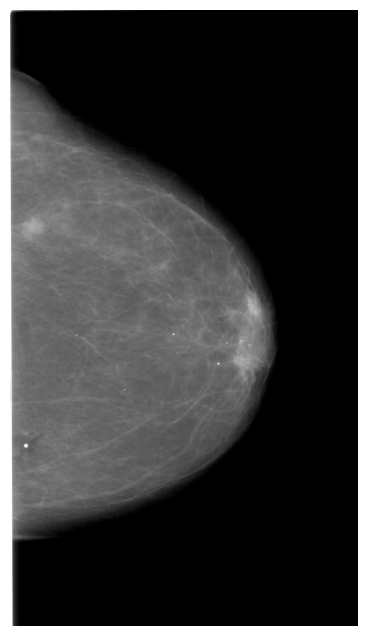

Image size: (3526, 6256)


In [12]:
sample_path = r"CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.248386742010678582309005372213277814849/1-249.jpg"

full_path = os.path.join(
    DATASET_DIR,
    sample_path.replace("CBIS-DDSM/jpeg/", "jpeg/")
)

print(full_path)
print("Exists:", os.path.exists(full_path))

img = Image.open(full_path)

plt.figure(figsize=(8,8))
plt.imshow(img, cmap="gray")
plt.axis("off")
plt.show()

print("Image size:", img.size)

In [13]:
sizes = []

for root, dirs, files in os.walk(JPEG_DIR):
    for file in files:
        if file.endswith(".jpg"):
            path = os.path.join(root, file)

            try:
                img = Image.open(path)
                sizes.append(img.size)
            except:
                pass

            if len(sizes) >= 100:
                break

    if len(sizes) >= 100:
        break

print("First 10 image sizes:")
print(sizes[:10])

print("\nUnique sizes found:")
print(set(sizes))

First 10 image sizes:
[(226, 211), (2626, 5056), (3826, 6601), (4126, 5491), (3151, 5491), (89, 81), (4072, 5728), (2952, 4504), (3480, 5992), (2568, 4648)]

Unique sizes found:
{(497, 537), (3056, 4528), (2912, 4544), (2626, 4996), (3096, 4664), (3904, 5640), (3360, 5912), (370, 327), (453, 407), (2568, 4648), (3416, 6032), (262, 247), (305, 401), (265, 209), (553, 441), (226, 211), (438, 448), (292, 229), (756, 913), (3048, 4576), (436, 386), (2807, 4595), (2888, 4504), (3151, 5491), (2506, 4741), (249, 233), (417, 409), (2992, 4616), (4081, 6691), (3544, 6032), (449, 459), (2281, 5296), (2926, 5491), (2904, 4176), (3968, 5712), (2491, 5206), (2616, 4712), (3072, 4544), (129, 145), (2896, 4672), (761, 785), (289, 225), (2731, 5236), (4426, 6511), (89, 81), (4024, 5704), (191, 266), (3280, 5896), (3136, 6526), (2566, 5296), (3712, 5584), (1846, 4006), (304, 310), (273, 249), (2952, 4504), (2512, 4760), (4136, 5840), (4126, 5491), (2341, 5326), (2664, 4720), (3992, 5768), (2911, 5491),

In [14]:
full_mammo = dicom_info[
    dicom_info["SeriesDescription"] == "full mammogram images"
]

print("Full mammogram rows:", len(full_mammo))

sizes = []

for _, row in full_mammo.head(100).iterrows():

    img_path = row["image_path"]

    img_path = img_path.replace(
        "CBIS-DDSM/jpeg/",
        "jpeg/"
    )

    full_path = os.path.join(DATASET_DIR, img_path)

    try:
        img = Image.open(full_path)
        sizes.append(img.size)
    except:
        pass

print("Unique sizes among first 100 full mammograms:")
print(set(sizes))

Full mammogram rows: 2857
Unique sizes among first 100 full mammograms:
{(3056, 4464), (2456, 4704), (3136, 4664), (2056, 5041), (2840, 4632), (3704, 5704), (2824, 4696), (1981, 4876), (2864, 4424), (2912, 4592), (3496, 5491), (2960, 4712), (2712, 4784), (2664, 4744), (4501, 6871), (2808, 4544), (3008, 4480), (3080, 4560), (2671, 5896), (3032, 4520), (3136, 4696), (1872, 4736), (4040, 5648), (3631, 6706), (3128, 4728), (2851, 5011), (4256, 6032), (3481, 5971), (4056, 5768), (2941, 5221), (2888, 4568), (2432, 4672), (2926, 5491), (3088, 4760), (3112, 4824), (3466, 5386), (2472, 4720), (3224, 5944), (2728, 4752), (3256, 5976), (2371, 5491), (3886, 6271), (3104, 4624), (2896, 4528), (3040, 4496), (2728, 4736), (2936, 4448), (3528, 5976), (2712, 4712), (3091, 6676), (4048, 5752), (2840, 4672), (3048, 5912), (3526, 6256), (3106, 6466), (2624, 4608), (4072, 5920), (4306, 6871), (3361, 5206), (3720, 5752), (4088, 5864), (4048, 5864), (2911, 5491), (2326, 5356), (2752, 4680), (2784, 4568), (35

## Image Resizing Rationale

All mammograms were resized to 224 x 224 pixels to provide a consistent input size for the CNN and reduce computational requirements during training. This resolution also matches the input size used for VGG16, allowing both model pipelines to operate on images with the same spatial dimensions.

In [15]:
print(train_mass.columns.tolist())

['patient_id', 'breast_density', 'left or right breast', 'image view', 'abnormality id', 'abnormality type', 'mass shape', 'mass margins', 'assessment', 'pathology', 'subtlety', 'image file path', 'cropped image file path', 'ROI mask file path', 'label']


In [16]:
train_mass[[
    "image file path",
    "label"
]].head()

,image file path,label
0,Mass-Training_P_00001_LEFT_CC/1.3.6.1.4.1.9590.100.1.2.422112722213189649807611434612228974994/1.3.6.1.4.1.9590.100.1.2.342386194811267636608694132590482924515/000000.dcm,1
1,Mass-Training_P_00001_LEFT_MLO/1.3.6.1.4.1.9590.100.1.2.319478999311971442426185353560182990988/1.3.6.1.4.1.9590.100.1.2.359308329312397897125630708681441180834/000000.dcm,1
2,Mass-Training_P_00004_LEFT_CC/1.3.6.1.4.1.9590.100.1.2.347107867812656628709864319310977895697/1.3.6.1.4.1.9590.100.1.2.89180046211022531834352631483669346540/000000.dcm,0
3,Mass-Training_P_00004_LEFT_MLO/1.3.6.1.4.1.9590.100.1.2.272600286511817402806912403581910920939/1.3.6.1.4.1.9590.100.1.2.295360926313492745441868049270168300162/000000.dcm,0
4,Mass-Training_P_00004_RIGHT_MLO/1.3.6.1.4.1.9590.100.1.2.174047308712169195014610267031196524486/1.3.6.1.4.1.9590.100.1.2.410524754913057908920631336070876889890/000000.dcm,0


In [17]:
full_mammo = dicom_info[
    dicom_info["SeriesDescription"] == "full mammogram images"
]

print("Full mammograms:", len(full_mammo))

full_mammo[["image_path"]].head()

Full mammograms: 2857


,image_path
1,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.248386742010678582309005372213277814849/1-249.jpg
2,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.267213171011171858918434139331210917771/1-032.jpg
11,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.210396893911234385024533119100226540488/1-128.jpg
12,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.74956658311383957201426978750903861062/1-248.jpg
15,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.98765885412946410823689524902893984551/1-007.jpg


In [18]:
print(full_mammo["image_path"].iloc[0])

CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.248386742010678582309005372213277814849/1-249.jpg


In [19]:
meta = pd.read_csv(
    os.path.join(CSV_DIR, "meta.csv")
)

print(meta.head())
print("\n")
print(meta.columns.tolist())

                                                  SeriesInstanceUID  \
0  1.3.6.1.4.1.9590.100.1.2.117041576511324414842508325652101471266   
1   1.3.6.1.4.1.9590.100.1.2.43873839610761788013224723323225482381   
2   1.3.6.1.4.1.9590.100.1.2.76741674113167646338262765132488965294   
3  1.3.6.1.4.1.9590.100.1.2.296931352612305599800425693833437698626   
4   1.3.6.1.4.1.9590.100.1.2.43665767012035310007732414810147712942   

                                                   StudyInstanceUID Modality  \
0  1.3.6.1.4.1.9590.100.1.2.229361142710768138411679379233064924540       MG   
1  1.3.6.1.4.1.9590.100.1.2.195593486612988388325770883972107282733       MG   
2  1.3.6.1.4.1.9590.100.1.2.257901172612530623323924356380431605062       MG   
3  1.3.6.1.4.1.9590.100.1.2.109468616710242115222536802734027827120       MG   
4  1.3.6.1.4.1.9590.100.1.2.380627129513562450304304820723973964760       MG   

  SeriesDescription BodyPartExamined  SeriesNumber Collection  Visibility  \
0   ROI mask im

In [20]:
for root, dirs, files in os.walk(JPEG_DIR):
    if files:
        print("Folder:", root)
        print("Files:", files[:5])
        break

Folder: C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg\1.3.6.1.4.1.9590.100.1.2.100018879311824535125115145152454291132
Files: ['1-263.jpg', '2-241.jpg']


In [21]:
sample_folder = os.path.join(
    JPEG_DIR,
    os.listdir(JPEG_DIR)[0]
)

print("Sample folder:")
print(sample_folder)

print("\nFiles inside:")
print(os.listdir(sample_folder))

Sample folder:
C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg\1.3.6.1.4.1.9590.100.1.2.100018879311824535125115145152454291132

Files inside:
['1-263.jpg', '2-241.jpg']


In [22]:
print(train_mass["image file path"].iloc[0])

Mass-Training_P_00001_LEFT_CC/1.3.6.1.4.1.9590.100.1.2.422112722213189649807611434612228974994/1.3.6.1.4.1.9590.100.1.2.342386194811267636608694132590482924515/000000.dcm


In [23]:
print(train_mass["image file path"].iloc[1])

Mass-Training_P_00001_LEFT_MLO/1.3.6.1.4.1.9590.100.1.2.319478999311971442426185353560182990988/1.3.6.1.4.1.9590.100.1.2.359308329312397897125630708681441180834/000000.dcm


In [24]:
uid = "1.3.6.1.4.1.9590.100.1.2.342386194811267636608694132590482924515"

matches = dicom_info[
    dicom_info["image_path"].str.contains(uid, na=False)
]

print("Matches found:", len(matches))

if len(matches) > 0:
    display(matches[[
        "image_path",
        "SeriesDescription"
    ]].head())

Matches found: 1


,image_path,SeriesDescription
7774,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.342386194811267636608694132590482924515/1-211.jpg,full mammogram images


In [25]:
def get_jpeg_path_from_dicom_path(dicom_path):
    parts = dicom_path.split("/")
    
    # The second UID folder maps to the JPEG image in dicom_info
    target_uid = parts[-2]
    
    matches = dicom_info[
        dicom_info["image_path"].str.contains(target_uid, na=False)
    ]
    
    # Prefer full mammogram images
    matches = matches[
        matches["SeriesDescription"] == "full mammogram images"
    ]
    
    if len(matches) == 0:
        return None
    
    jpeg_relative_path = matches.iloc[0]["image_path"]
    jpeg_relative_path = jpeg_relative_path.replace("CBIS-DDSM/jpeg/", "jpeg/")
    
    return os.path.join(DATASET_DIR, jpeg_relative_path)

In [26]:
test_path = get_jpeg_path_from_dicom_path(
    train_mass["image file path"].iloc[0]
)

print(test_path)
print("Exists:", os.path.exists(test_path))
print("Label:", train_mass["label"].iloc[0])

C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg/1.3.6.1.4.1.9590.100.1.2.342386194811267636608694132590482924515/1-211.jpg
Exists: True
Label: 1


In [27]:
train_mass["jpeg_path"] = train_mass["image file path"].apply(
    get_jpeg_path_from_dicom_path
)

print("Total rows:", len(train_mass))
print("Rows with valid JPEG paths:", train_mass["jpeg_path"].notna().sum())
print("Rows missing JPEG paths:", train_mass["jpeg_path"].isna().sum())

train_dataset = train_mass[
    train_mass["jpeg_path"].notna()
][["jpeg_path", "label", "pathology"]].copy()

display(train_dataset.head())

Total rows: 1318
Rows with valid JPEG paths: 1318
Rows missing JPEG paths: 0


,jpeg_path,label,pathology
0,C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg/1.3.6.1.4.1.9590.100.1.2.342386194811267636608694132590482924515/1-211.jpg,1,MALIGNANT
1,C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg/1.3.6.1.4.1.9590.100.1.2.359308329312397897125630708681441180834/1-207.jpg,1,MALIGNANT
2,C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg/1.3.6.1.4.1.9590.100.1.2.89180046211022531834352631483669346540/1-250.jpg,0,BENIGN
3,C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg/1.3.6.1.4.1.9590.100.1.2.295360926313492745441868049270168300162/1-067.jpg,0,BENIGN
4,C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg/1.3.6.1.4.1.9590.100.1.2.410524754913057908920631336070876889890/1-056.jpg,0,BENIGN


# Load patient-grouped train/validation split

In [28]:
split_dir = "Splits"

train_df = pd.read_csv(
    os.path.join(split_dir, "train_patient_grouped.csv")
)

val_df = pd.read_csv(
    os.path.join(split_dir, "val_patient_grouped.csv")
)

print("Training rows:", len(train_df))
print("Validation rows:", len(val_df))

print("\nTraining columns:")
print(train_df.columns.tolist())

print("\nValidation columns:")
print(val_df.columns.tolist())

Training rows: 984
Validation rows: 241

Training columns:
['jpeg_path', 'label', 'pathology', 'patient_id']

Validation columns:
['jpeg_path', 'label', 'pathology', 'patient_id']


In [29]:
train_df["jpeg_path"] = train_df["jpeg_path"].apply(
    lambda p: os.path.join(DATASET_DIR, p)
)

val_df["jpeg_path"] = val_df["jpeg_path"].apply(
    lambda p: os.path.join(DATASET_DIR, p)
)

print("Training paths found:",
      train_df["jpeg_path"].apply(os.path.exists).sum(),
      "/", len(train_df))

print("Validation paths found:",
      val_df["jpeg_path"].apply(os.path.exists).sum(),
      "/", len(val_df))

print("\nExample training path:")
print(train_df["jpeg_path"].iloc[0])

Training paths found: 984 / 984
Validation paths found: 241 / 241

Example training path:
C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg\1.3.6.1.4.1.9590.100.1.2.342386194811267636608694132590482924515\1-211.jpg


# Load and preprocess patient-grouped mammograms

In [30]:
def load_and_preprocess_image(path):
    image = Image.open(path).convert("L")
    image = image.resize((224, 224))
    image = np.array(image, dtype=np.float32) / 255.0
    image = np.expand_dims(image, axis=-1)
    return image

In [31]:
X_train = np.array([
    load_and_preprocess_image(path)
    for path in train_df["jpeg_path"]
], dtype=np.float32)

X_val = np.array([
    load_and_preprocess_image(path)
    for path in val_df["jpeg_path"]
], dtype=np.float32)

y_train = train_df["label"].to_numpy(dtype=np.float32)
y_val = val_df["label"].to_numpy(dtype=np.float32)

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)

print("\nValidation images:", X_val.shape)
print("Validation labels:", y_val.shape)

print("\nTraining dtype:", X_train.dtype)
print("Validation dtype:", X_val.dtype)

Training images: (984, 224, 224, 1)
Training labels: (984,)

Validation images: (241, 224, 224, 1)
Validation labels: (241,)

Training dtype: float32
Validation dtype: float32


# Rebuild baseline CNN on patient-grouped split

In [32]:
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

baseline_grouped_model = Sequential([
    Input(shape=(224, 224, 1)),

    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation="relu"),
    Dropout(0.5),

    Dense(1, activation="sigmoid")
])

baseline_grouped_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 222, 222, 32)        │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 111, 111, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 109, 109, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 54, 54, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 52, 52, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 26, 26, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 86528)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │      11,075,712 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 11,168,513 (42.60 MB)

 Trainable params: 11,168,513 (42.60 MB)

 Non-trainable params: 0 (0.00 B)

## Compile corrected baseline CNN

The baseline architecture is compiled using the same binary-classification objective while recording additional evaluation metrics for the patient-grouped split.

In [34]:
import tensorflow as tf

baseline_grouped_model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="roc_auc")
    ]
)

print("Corrected baseline model compiled successfully")

Corrected baseline model compiled successfully


In [35]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

print("Early stopping configured")

Early stopping configured


In [36]:
history_baseline_grouped = baseline_grouped_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=16,
    callbacks=[early_stop]
)

Epoch 1/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 12s 172ms/step - accuracy: 0.5325 - loss: 0.7117 - precision: 0.5189 - recall: 0.5167 - roc_auc: 0.5165 - val_accuracy: 0.5560 - val_loss: 0.6940 - val_precision: 0.5495 - val_recall: 0.5169 - val_roc_auc: 0.5508
Epoch 2/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 11s 174ms/step - accuracy: 0.5762 - loss: 0.6794 - precision: 0.5695 - recall: 0.5230 - roc_auc: 0.6054 - val_accuracy: 0.5477 - val_loss: 0.6921 - val_precision: 0.5254 - val_recall: 0.7881 - val_roc_auc: 0.5777
Epoch 3/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 11s 169ms/step - accuracy: 0.6077 - loss: 0.6604 - precision: 0.5891 - recall: 0.6360 - roc_auc: 0.6404 - val_accuracy: 0.6017 - val_loss: 0.6779 - val_precision: 0.5917 - val_recall: 0.6017 - val_roc_auc: 0.5986
Epoch 4/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 10s 167ms/step - accuracy: 0.6697 - loss: 0.6155 - precision: 0.6783 - recall: 0.6088 - roc_auc: 0.7153 - val_accuracy: 0.5726 - val_loss: 0.6850 - val_precision: 0.5564 - val_recall: 0.6271 - val_roc_auc: 0.6

### Reproducibility note

Training deep neural networks involves stochastic operations such as weight initialisation, dropout and mini-batch ordering. Consequently, retraining the model may produce slightly different validation metrics.

The evaluation results presented below correspond to the trained model used for the final project experiments. The patient-grouped data split itself is fixed and reused across subsequent model comparisons.

In [37]:
baseline_grouped_results = baseline_grouped_model.evaluate(
    X_val,
    y_val,
    verbose=1,
    return_dict=True
)

print(baseline_grouped_results)

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 69ms/step - accuracy: 0.6141 - loss: 0.6763 - precision: 0.6238 - recall: 0.5339 - roc_auc: 0.6322
{'accuracy': 0.6141079068183899, 'loss': 0.6762765645980835, 'precision': 0.6237623691558838, 'recall': 0.5338982939720154, 'roc_auc': 0.6321827173233032}


In [38]:
os.makedirs("Models", exist_ok=True)

model_path = os.path.join(
    "Models",
    "baseline_cnn_patient_grouped.keras"
)

baseline_grouped_model.save(model_path)

print("Corrected baseline model saved to:")
print(model_path)

Corrected baseline model saved to:
C:\Users\Ivan\Documents\Y3S2 local\FYP\04 Implementation\Models\baseline_cnn_patient_grouped.keras


### Corrected baseline evaluation

The baseline CNN was retrained using the patient-grouped, image-deduplicated split.

Validation performance:
- Accuracy: 61.41%
- Precision: 62.38%
- Recall: 53.39%
- ROC-AUC: 0.6324 (computed using `sklearn.metrics.roc_auc_score`)
- Loss: 0.6763

These results replace the original row-level split as the main baseline for subsequent model comparisons. The original prototype results are retained for development-history purposes but are not treated as the primary estimate of generalisation.

## Detailed evaluation of the corrected baseline CNN

The following evaluation uses predictions from the patient-grouped validation set to calculate the confusion matrix, F1-score, specificity and other classification metrics at the default decision threshold of 0.5.

In [2]:
from tensorflow.keras.models import load_model

model_path = os.path.join(
    "Models",
    "baseline_cnn_patient_grouped.keras"
)

baseline_grouped_model = load_model(model_path)

print("Corrected baseline model loaded successfully.")

Corrected baseline model loaded successfully.


In [3]:
val_split_path = os.path.join("Splits", "val_patient_grouped.csv")

val_df = pd.read_csv(val_split_path)

print(val_df.head())
print(val_df.columns)
print("Validation rows:", len(val_df))

                                           jpeg_path  label  pathology  \
0  jpeg\1.3.6.1.4.1.9590.100.1.2.3920919319116377...      1  MALIGNANT   
1  jpeg\1.3.6.1.4.1.9590.100.1.2.1855302201129836...      1  MALIGNANT   
2  jpeg\1.3.6.1.4.1.9590.100.1.2.1239688160115129...      1  MALIGNANT   
3  jpeg\1.3.6.1.4.1.9590.100.1.2.4176392289118075...      1  MALIGNANT   
4  jpeg\1.3.6.1.4.1.9590.100.1.2.1983751761271825...      1  MALIGNANT   

  patient_id  
0    P_00009  
1    P_00009  
2    P_00023  
3    P_00023  
4    P_00039  
Index(['jpeg_path', 'label', 'pathology', 'patient_id'], dtype='str')
Validation rows: 241


In [4]:
from pathlib import Path

dataset_root = Path(DATASET_DIR)

def load_baseline_image(relative_path):
    image_path = dataset_root / relative_path

    image = Image.open(image_path).convert("L")
    image = image.resize((224, 224))

    image = np.array(image, dtype=np.float32) / 255.0
    image = image[..., np.newaxis]

    return image

X_val = np.stack([
    load_baseline_image(path)
    for path in val_df["jpeg_path"]
])

y_val = val_df["label"].to_numpy(dtype=np.int32)

print("X_val shape:", X_val.shape)
print("y_val shape:", y_val.shape)
print("X_val dtype:", X_val.dtype)
print("y_val dtype:", y_val.dtype)
print("Label counts:", np.bincount(y_val))

X_val shape: (241, 224, 224, 1)
y_val shape: (241,)
X_val dtype: float32
y_val dtype: int32
Label counts: [123 118]


In [5]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    f1_score
)

# Predict malignant-class probabilities
baseline_val_prob = baseline_grouped_model.predict(
    X_val,
    verbose=0
).ravel()

# Convert probabilities to binary predictions using threshold = 0.5
baseline_val_pred = (baseline_val_prob >= 0.5).astype(int)

# Confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_val.astype(int),
    baseline_val_pred
).ravel()

# Additional metrics
baseline_f1 = f1_score(
    y_val.astype(int),
    baseline_val_pred
)

baseline_specificity = tn / (tn + fp)

print("Confusion matrix values:")
print(f"TN: {tn}")
print(f"FP: {fp}")
print(f"FN: {fn}")
print(f"TP: {tp}")

print(f"\nF1-score: {baseline_f1:.4f}")
print(f"Specificity: {baseline_specificity:.4f}")

print("\nClassification report:")
print(
    classification_report(
        y_val.astype(int),
        baseline_val_pred,
        target_names=["Benign", "Malignant"],
        digits=4
    )
)

Confusion matrix values:
TN: 85
FP: 38
FN: 55
TP: 63

F1-score: 0.5753
Specificity: 0.6911

Classification report:
              precision    recall  f1-score   support

      Benign     0.6071    0.6911    0.6464       123
   Malignant     0.6238    0.5339    0.5753       118

    accuracy                         0.6141       241
   macro avg     0.6155    0.6125    0.6109       241
weighted avg     0.6153    0.6141    0.6116       241



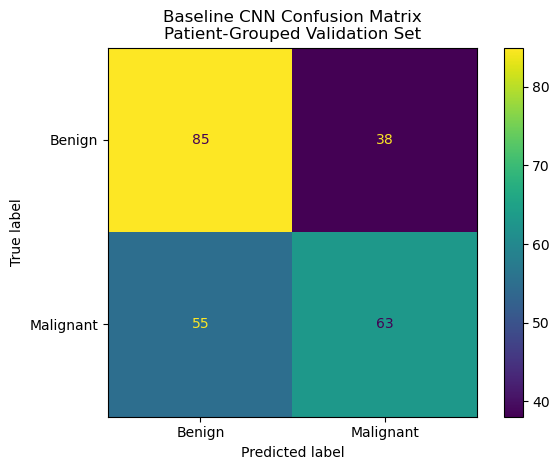

In [6]:
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    y_val.astype(int),
    baseline_val_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malignant"]
)

disp.plot(values_format="d")
plt.title("Baseline CNN Confusion Matrix\nPatient-Grouped Validation Set")
plt.tight_layout()
plt.show()

Baseline CNN ROC-AUC: 0.6324


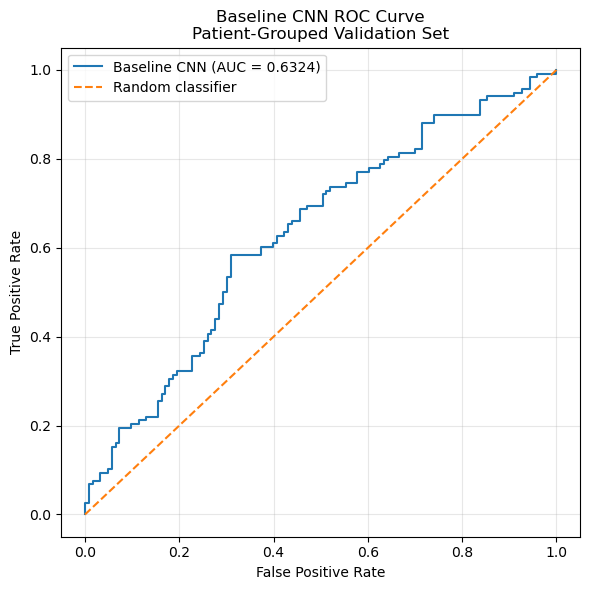

In [7]:
from sklearn.metrics import roc_curve, roc_auc_score

# Compute ROC curve
fpr, tpr, thresholds = roc_curve(
    y_val.astype(int),
    baseline_val_prob
)

# Compute ROC-AUC
baseline_roc_auc = roc_auc_score(
    y_val.astype(int),
    baseline_val_prob
)

print(f"Baseline CNN ROC-AUC: {baseline_roc_auc:.4f}")

# Plot ROC curve
plt.figure(figsize=(6, 6))
plt.plot(
    fpr,
    tpr,
    label=f"Baseline CNN (AUC = {baseline_roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Baseline CNN ROC Curve\nPatient-Grouped Validation Set")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

threshold_values = np.arange(0.20, 0.81, 0.05)

threshold_results = []

for threshold in threshold_values:
    preds = (baseline_val_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val.astype(int),
        preds
    ).ravel()

    accuracy = accuracy_score(y_val, preds)
    precision = precision_score(y_val, preds, zero_division=0)
    recall = recall_score(y_val, preds)
    f1 = f1_score(y_val, preds)
    specificity = tn / (tn + fp)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "Specificity": specificity,
        "False Negatives": fn,
        "False Positives": fp
    })

baseline_threshold_df = pd.DataFrame(threshold_results)

print(
    baseline_threshold_df.round(4).to_string(index=False)
)

 Threshold  Accuracy  Precision  Recall     F1  Specificity  False Negatives  False Positives
      0.20    0.5062     0.4978  0.9746 0.6590       0.0569                3              116
      0.25    0.5021     0.4956  0.9576 0.6532       0.0650                5              115
      0.30    0.5145     0.5023  0.9407 0.6549       0.1057                7              110
      0.35    0.5353     0.5146  0.8983 0.6543       0.1870               12              100
      0.40    0.5519     0.5269  0.8305 0.6447       0.2846               20               88
      0.45    0.6058     0.5762  0.7373 0.6468       0.4797               31               64
      0.50    0.6141     0.6238  0.5339 0.5753       0.6911               55               38
      0.55    0.5643     0.5942  0.3475 0.4385       0.7724               77               28
      0.60    0.5519     0.6000  0.2542 0.3571       0.8374               88               20
      0.65    0.5560     0.6571  0.1949 0.3007       0.9024 

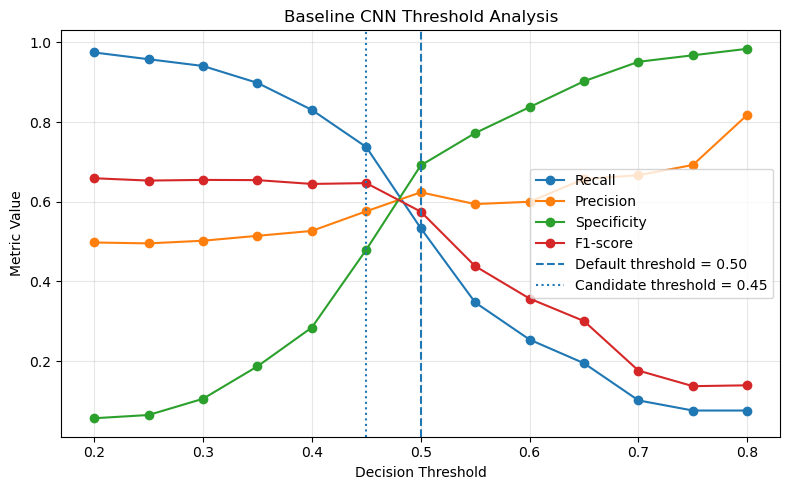

In [9]:
plt.figure(figsize=(8, 5))

plt.plot(
    baseline_threshold_df["Threshold"],
    baseline_threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    baseline_threshold_df["Threshold"],
    baseline_threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    baseline_threshold_df["Threshold"],
    baseline_threshold_df["Specificity"],
    marker="o",
    label="Specificity"
)

plt.plot(
    baseline_threshold_df["Threshold"],
    baseline_threshold_df["F1"],
    marker="o",
    label="F1-score"
)

plt.axvline(
    x=0.50,
    linestyle="--",
    label="Default threshold = 0.50"
)

plt.axvline(
    x=0.45,
    linestyle=":",
    label="Candidate threshold = 0.45"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Metric Value")
plt.title("Baseline CNN Threshold Analysis")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

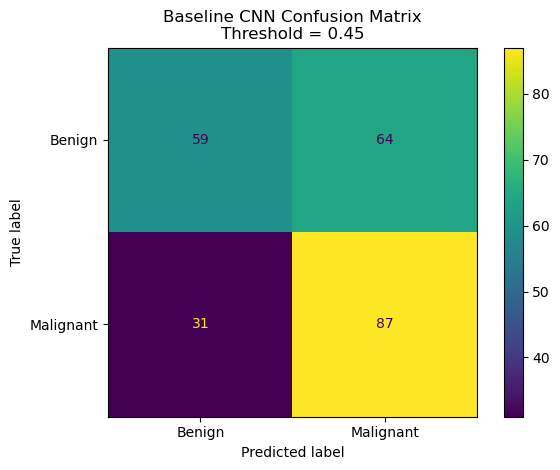

In [10]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

baseline_pred_045 = (baseline_val_prob >= 0.45).astype(int)

cm_045 = confusion_matrix(
    y_val.astype(int),
    baseline_pred_045
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_045,
    display_labels=["Benign", "Malignant"]
)

disp.plot(values_format="d")
plt.title("Baseline CNN Confusion Matrix\nThreshold = 0.45")
plt.tight_layout()
plt.show()